In [2]:
import sqlite3
import pandas as pd
import plotly.express as px

In [3]:
DB_PATH = "../analytics_sample.db"

In [4]:
conn = sqlite3.connect(DB_PATH)
telemetry_df = pd.read_sql_query("SELECT * FROM telemetry", conn)
audit_df = pd.read_sql_query("SELECT * FROM audit_log", conn)
conn.close()

In [5]:
print(f"Telemetry rows: {len(telemetry_df)}")
print(f"Audit rows: {len(audit_df)}")
telemetry_df.head()

Telemetry rows: 9000
Audit rows: 449


,id,tick,robot_id,x,y,battery,state,recorded_at
0,1,1,R1,1,1,100.0,IDLE,2026-10-04T18:02:55.404807+00:00
1,2,1,R2,6,1,100.0,IDLE,2026-10-04T18:02:55.411186+00:00
2,3,1,R3,12,6,100.0,IDLE,2026-10-04T18:02:55.417247+00:00
3,4,2,R1,1,1,100.0,IDLE,2026-10-04T18:02:55.421854+00:00
4,5,2,R2,6,1,100.0,IDLE,2026-10-04T18:02:55.427076+00:00


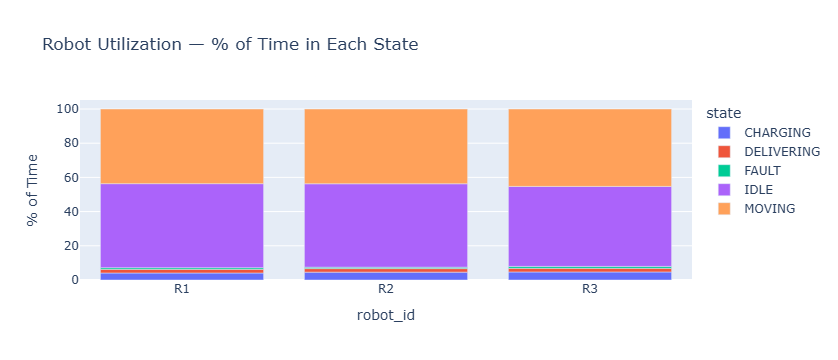

In [6]:
state_time = telemetry_df.groupby(["robot_id", "state"]).size().reset_index(name="ticks")
state_time["percent"] = state_time.groupby("robot_id")["ticks"].transform(lambda x: 100 * x / x.sum())

fig = px.bar(
    state_time, x="robot_id", y="percent", color="state",
    title="Robot Utilization — % of Time in Each State",
    labels={"percent": "% of Time"},
)
fig.show()

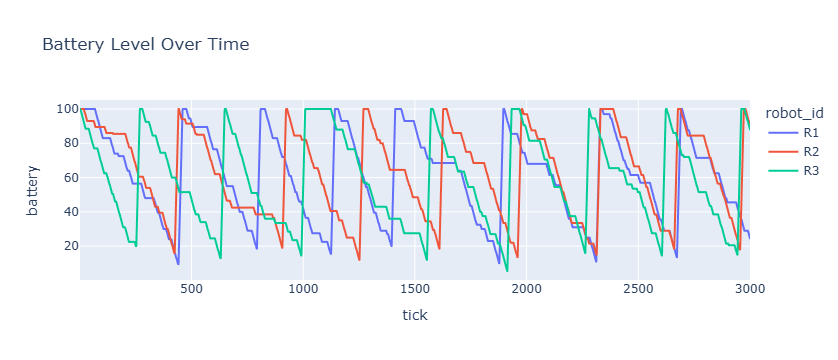

In [7]:
fig = px.line(
    telemetry_df, x="tick", y="battery", color="robot_id",
    title="Battery Level Over Time",
)
fig.show()

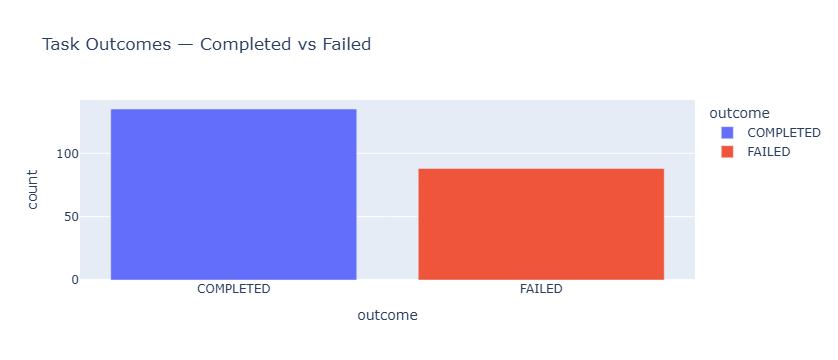

Overall task success rate: 60.5%


In [8]:
outcomes_df = audit_df[audit_df["tool_name"] == "task_outcome"].copy()
outcome_counts = outcomes_df["reason"].value_counts().reset_index()
outcome_counts.columns = ["outcome", "count"]

fig = px.bar(
    outcome_counts, x="outcome", y="count", color="outcome",
    title="Task Outcomes — Completed vs Failed",
)
fig.show()

success_rate = (
    outcome_counts.loc[outcome_counts["outcome"] == "COMPLETED", "count"].sum()
    / outcome_counts["count"].sum() * 100
)
print(f"Overall task success rate: {success_rate:.1f}%")


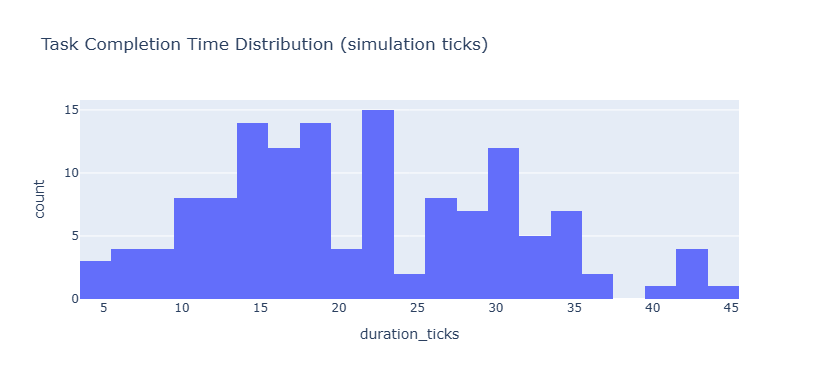

Average completion time: 21.4 ticks
Median completion time: 20.0 ticks


In [9]:
import json

completed_df = outcomes_df[outcomes_df["reason"] == "COMPLETED"].copy()
completed_df["duration_ticks"] = completed_df["result"].apply(lambda r: json.loads(r)["duration_ticks"])

fig = px.histogram(
    completed_df, x="duration_ticks", nbins=20,
    title="Task Completion Time Distribution (simulation ticks)",
)
fig.show()

print(f"Average completion time: {completed_df['duration_ticks'].mean():.1f} ticks")
print(f"Median completion time: {completed_df['duration_ticks'].median():.1f} ticks")


In [11]:
telemetry_df.shape


(9000, 8)